In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pyMLaux import plot_2d_prediction

In [2]:
def fit_adaline(X, y, eta=None, maxiter=200, init_strategy='centroid'):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    n_samples, n_features = X.shape

    # Augment input with x_0 = 1 for bias/threshold weight
    X_ext = np.c_[np.ones(n_samples), X]

    # Adaptive learning rate based on feature scale if not explicitly provided
    if eta is None:
        mean_sq_norm = np.mean(np.sum(X_ext**2, axis=1))
        eta = 0.5 / mean_sq_norm

    # Initialization strategy based on input features
    if init_strategy == 'centroid':
        pos_mean = X[y == 1].mean(axis=0) if np.any(y == 1) else np.zeros(n_features)
        neg_mean = X[y == -1].mean(axis=0) if np.any(y == -1) else np.zeros(n_features)
        diff = pos_mean - neg_mean
        diff_norm_sq = np.dot(diff, diff) + 1e-8
        w_features = diff / diff_norm_sq
        midpoint = 0.5 * (pos_mean + neg_mean)
        w_bias = -np.dot(w_features, midpoint)
        w = np.r_[w_bias, w_features]
    elif init_strategy == 'random':
        w = np.random.randn(n_features + 1) * (1.0 / np.sqrt(n_features))
        w[0] = 0.0
    else:
        w = np.zeros(n_features + 1)

    # ADALINE online training loop (LMS / Widrow-Hoff delta rule)
    for epoch in range(maxiter):
        for i in range(n_samples):
            output = np.dot(X_ext[i], w)
            error = y[i] - output
            w += eta * error * X_ext[i]

    return w

In [3]:
# Create a 3-dimensional linearly separable dataset
np.random.seed(42)
n_samples_per_class = 30

# Generate two distinct clusters in 3D
X_pos = np.random.randn(n_samples_per_class, 3) * 0.4 + np.array([2.0, 2.0, 2.0])
X_neg = np.random.randn(n_samples_per_class, 3) * 0.4 + np.array([0.0, 0.0, 0.0])

X_3d = np.vstack([X_pos, X_neg])
y_3d = np.array([1] * n_samples_per_class + [-1] * n_samples_per_class)

# Fit ADALINE taking only the dataset (X, y) as input
w_3d = fit_adaline(X_3d, y_3d)

print("Fitted weight vector [w0 (bias), w1, w2, w3]:")
print(w_3d)

# Evaluate classification accuracy
X_3d_ext = np.c_[np.ones(len(X_3d)), X_3d]
preds_3d = np.where(X_3d_ext.dot(w_3d) >= 0, 1, -1)
accuracy = np.mean(preds_3d == y_3d) * 100
print(f"Classification accuracy on 3D dataset: {accuracy:.1f}%")

Fitted weight vector [w0 (bias), w1, w2, w3]:
[-1.04790146  0.37174614  0.22957179  0.15450567]
Classification accuracy on 3D dataset: 100.0%


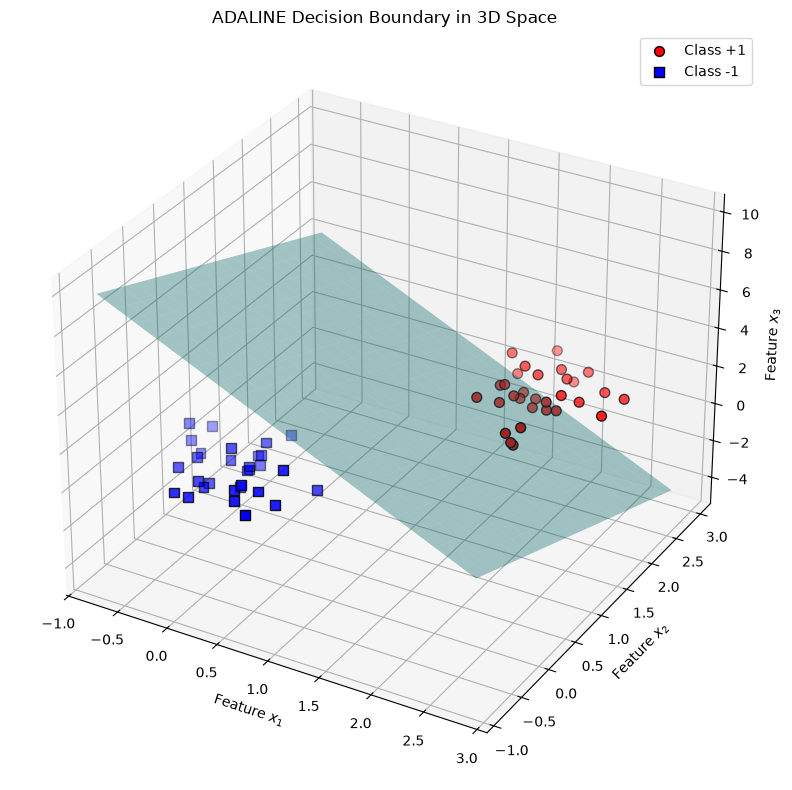

In [4]:
# 3D Visualization of the data and the learned separating hyperplane
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot of samples for both classes
ax.scatter(X_pos[:, 0], X_pos[:, 1], X_pos[:, 2], c='red', marker='o', s=50, label='Class +1', edgecolors='k')
ax.scatter(X_neg[:, 0], X_neg[:, 1], X_neg[:, 2], c='blue', marker='s', s=50, label='Class -1', edgecolors='k')

# Calculate the separating hyperplane: w0 + w1*x1 + w2*x2 + w3*x3 = 0  =>  x3 = -(w0 + w1*x1 + w2*x2) / w3
x1_range = np.linspace(X_3d[:, 0].min() - 0.2, X_3d[:, 0].max() + 0.2, 20)
x2_range = np.linspace(X_3d[:, 1].min() - 0.2, X_3d[:, 1].max() + 0.2, 20)
X1_mesh, X2_mesh = np.meshgrid(x1_range, x2_range)

if abs(w_3d[3]) > 1e-6:
    X3_mesh = -(w_3d[0] + w_3d[1] * X1_mesh + w_3d[2] * X2_mesh) / w_3d[3]
    ax.plot_surface(X1_mesh, X2_mesh, X3_mesh, alpha=0.35, color='cyan', edgecolor='none')

ax.set_xlabel('Feature $x_1$')
ax.set_ylabel('Feature $x_2$')
ax.set_zlabel('Feature $x_3$')
ax.set_title('ADALINE Decision Boundary in 3D Space')
ax.legend()
plt.tight_layout()
plt.show()